# SR 02 · CO₂ uptake from a humid gas

**Chemical Engineering Modelling Labs · Worked teaching edition**

**Advanced SR case · four independent inputs.** Search saturation, competition, temperature and uptake structures; validate complete operating conditions; inspect uncertainty, physical limits and a hotter-regime challenge.

## Start here · use in Google Colab
Open this `.ipynb` with **File → Upload notebook**, keep a **CPU runtime**, and use **Runtime → Run all**. Save an individual copy before editing. All data are generated inside the notebook; the core exercise needs no upload, process simulator, API key, GPU or Julia installation.

Every executable line has an adjacent English comment. Markdown between cells explains the scientific purpose and the result to inspect. Saved tables and plots are retained in this worked edition so that it is also readable without running it.

**Teaching contract.** These are synthetic observations, not laboratory measurements. Ground truth is disclosed for teaching and independent audits; model fitting uses noisy training targets only. Validation selects a model; test and challenge sets report performance after selection. Repeatedly redesigning a model after reading test errors invalidates the original test.

**Follow the sequence:** context → data → model structure → fitting → validation → test diagnostics → engineering interpretation → exercises → export.

## 1. Set up Python

In [1]:
import importlib.util  # Check the runtime before installing any packages.
import subprocess  # Run pip through this notebook's Python interpreter when required.
import sys  # Identify the active interpreter and record its version.
requirements = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'scipy': 'scipy', 'statsmodels': 'statsmodels', 'sklearn': 'scikit-learn', 'sympy': 'sympy'}  # Map Python imports to package names.
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]  # Find only the dependencies that are absent.
if missing:  # Keep a working Colab environment unchanged whenever possible.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])  # Install missing packages in the current runtime.
import numpy as np  # Perform numerical array calculations and generate controlled random noise.
import pandas as pd  # Display labelled datasets and result tables.
import matplotlib.pyplot as plt  # Create figures with the default Matplotlib colours.
import scipy  # Record the numerical-library version for reproducibility.
from scipy import stats  # Obtain statistical distributions and diagnostics.
from scipy.optimize import minimize, least_squares  # Optimise operating points and fit nonlinear equation parameters.
import statsmodels.api as sm  # Fit linear-in-coefficient regressions and estimate statistical intervals.
from sklearn.preprocessing import PolynomialFeatures  # Generate polynomial terms for the RSM baselines.
from itertools import combinations, product  # Enumerate experimental-design pairs and symbolic candidate structures.
from pathlib import Path  # Manage output files independently of the operating system.
import json  # Save fitted-model specifications in readable form.
import shutil  # Bundle figures and tables into a downloadable archive.
from IPython.display import display, Markdown, Math, FileLink  # Embed formatted tables, equations and links in the notebook.
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.dpi': 110})  # Keep figure text legible without changing colour or plot style.
pd.set_option('display.max_columns', 16)  # Keep the important columns visible in result tables.
versions = pd.DataFrame({'component': ['Python', 'NumPy', 'pandas', 'SciPy', 'statsmodels'], 'version': [sys.version.split()[0], np.__version__, pd.__version__, scipy.__version__, sm.__version__]})  # Record the environment used for this execution.
display(versions)  # Show the software versions before modelling begins.

,component,version
0,Python,3.13.5
1,NumPy,2.3.5
2,pandas,2.2.3
3,SciPy,1.17.0
4,statsmodels,0.14.6


**Checkpoint.** The version table should appear without an exception. Core dependencies are installed only when absent. Minor numerical differences between package versions are possible.

In [2]:
SEED = 20261010  # Reproduce the original four-case teaching dataset package.
case_seed = np.random.SeedSequence(SEED).spawn(4)[3]  # Select an independent random stream for this chemical-engineering case.
design_seed, noise_seed = case_seed.spawn(2)  # Keep operating-point sampling separate from observation noise.
rng_design = np.random.default_rng(design_seed)  # Generate reproducible experimental conditions.
rng_noise = np.random.default_rng(noise_seed)  # Generate reproducible but independent measurement errors.
RESULTS = Path('results_04_sr_co2_adsorption')  # Store this case's figures, data and fitted-model files in one place.
RESULTS.mkdir(exist_ok=True)  # Reuse the same folder safely when the notebook is rerun.
print('Output folder:', RESULTS.resolve())  # Identify the files that can be downloaded at the end.

Output folder: /mnt/data/Colab_Teaching_Notebooks/results_04_sr_co2_adsorption


**Reproducibility.** The default settings regenerate the corresponding observations in the earlier dataset package. Changing the seed represents a new synthetic experiment; do not choose a seed for favourable performance.

In [3]:
def lhs(n, bounds, rng):  # Spread observations across each input range using Latin hypercube sampling.
    bounds = np.asarray(bounds, dtype=float)  # Convert the physical lower and upper limits into an array.
    u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in bounds])  # Sample every stratum once in each input direction.
    return bounds[:, 0] + u * (bounds[:, 1] - bounds[:, 0])  # Map the samples into the physical operating box.

def save_plot(fig, filename):  # Display and preserve each result figure.
    fig.tight_layout()  # Reduce crowding between labels, axes and titles.
    fig.savefig(RESULTS / (filename + '.png'), dpi=160, bbox_inches='tight')  # Save a high-resolution copy for teaching slides or reports.
    plt.show()  # Embed the figure in the notebook output.
    plt.close(fig)  # Release figure memory before continuing to the next plot.

def metrics(y, prediction):  # Quantify predictions without refitting the model.
    y, prediction = np.asarray(y), np.asarray(prediction)  # Ensure compatible numerical arrays.
    errors = prediction - y  # Define a positive error as an overprediction.
    return {'RMSE': float(np.sqrt(np.mean(errors**2))), 'MAE': float(np.mean(np.abs(errors))), 'R_squared': float(1 - np.sum(errors**2) / np.sum((y-y.mean())**2))}  # Return error magnitudes and the mean-response comparison.

def parity(y, prediction, title, units, filename):  # Compare new observations with fixed-model predictions.
    fig, ax = plt.subplots(figsize=(6.8, 5.2))  # Create a single readable plotting panel.
    ax.scatter(y, prediction, s=26, alpha=0.7)  # Draw one marker per independent evaluation observation.
    limits = [min(np.min(y), np.min(prediction)), max(np.max(y), np.max(prediction))]  # Cover observed and predicted values with the same numerical range.
    ax.plot(limits, limits, '--', label='Perfect prediction')  # Mark the identity line as the reference.
    ax.set(xlabel='Observed '+units, ylabel='Predicted '+units, title=title)  # State the response units and evaluation purpose.
    ax.legend()  # Identify the reference line without cluttering the plot.
    save_plot(fig, filename)  # Save and embed this parity figure.

**Read the helpers.** RMSE and MAE retain the response units. $R^2$ can be negative. A scatter plot is an evaluation tool, not proof of a valid mechanism.

## 2. Capture-process context
An adsorbent exposed to humid CO₂-containing gas is a possible upstream stage in a carbon-utilisation process. Our simplified experiment measures uptake under **externally maintained, uniform gas conditions**.

| Independent input | Training range |
|---|---:|
| Temperature, $T$ | 298–348 K |
| CO₂ partial pressure, $p_C$ | 0.03–0.25 bar |
| Water-vapour partial pressure, $p_W$ | 0.001–0.025 bar |
| Exposure time, $t$ | 5–300 s |

The response is $q$, the CO₂ uptake in mmol g$^{-1}$. Assume an initially unloaded solid, constant gas partial pressures, no heat or axial gradients, and nitrogen as the balance gas at 1 bar total pressure.

**Scope:** this is a lumped uptake surrogate. It is not a fixed-bed breakthrough, regeneration-cycle or plant-performance model. All parameter values are synthetic teaching assumptions; the water-competition assumption is not validated for a specific adsorbent.

### Instructor's generating equations
$$q_{eq}=\frac{q_s b_C(T)p_C}{1+b_C(T)p_C+b_W(T)p_W},\qquad \frac{dq}{dt}=k(T)(q_{eq}-q).$$
For $q(0)=0$ and constant conditions,
$$q(t)=q_{eq}[1-\exp(-k(T)t)].$$
Use temperature-dependent adsorption coefficients and an effective uptake coefficient:
$$b_i(T)=b_{i,0}\exp\left[\frac{H_i}{R}\left(\frac1T-\frac1{T_0}\right)\right],$$
$$k(T)=k_0\exp\left[-\frac{E_k}{R}\left(\frac1T-\frac1{T_0}\right)\right].$$
Here $T_0=318$ K, $q_s=3$ mmol g$^{-1}$, $b_{C,0}=5$ bar$^{-1}$, $b_{W,0}=30$ bar$^{-1}$, $H_C=25$ and $H_W=35$ kJ mol$^{-1}$, $k_0=0.015$ s$^{-1}$ and $E_k=18$ kJ mol$^{-1}$. Positive $H_i$ denotes the magnitude of an assumed exothermic adsorption energy, not a positive signed adsorption enthalpy.

Add mean-preserving lognormal observation noise with $\sigma=0.05$, or approximately 5% relative scatter. The linear-driving-force coefficient is effective, not automatically an elementary reaction constant.

In [4]:
FEATURES = ['temperature_K', 'CO2_partial_pressure_bar', 'H2O_partial_pressure_bar', 'exposure_time_s']  # Name four independently controllable experimental inputs.
BOUNDS = np.array([[298, 348], [0.03, 0.25], [0.001, 0.025], [5, 300]], dtype=float)  # Define the fitted operating ranges.
CENTRE, HALF_RANGE = BOUNDS.mean(axis=1), np.diff(BOUNDS, axis=1).ravel()/2  # Fix centred coordinates for polynomial baselines.
R, SIGMA = 8.314462618, 0.05  # State the gas constant and synthetic log-noise standard deviation.
def adsorption_truth(x):  # Evaluate the instructor's synthetic equilibrium-plus-uptake process.
    T, pc, pw, t = np.atleast_2d(x).T  # Unpack physical inputs while allowing batch evaluation.
    if np.any(T <= 0) or np.any(pc < 0) or np.any(pw < 0) or np.any(t < 0):  # Reject inputs outside the mathematical physical domain.
        raise ValueError('Use positive absolute temperature and non-negative pressures and time.')  # Explain the validity requirement.
    bc = 5*np.exp(25000/R*(1/T-1/318.0))  # Compute the assumed CO2 equilibrium coefficient in inverse bar.
    bw = 30*np.exp(35000/R*(1/T-1/318.0))  # Compute the assumed competing-water equilibrium coefficient in inverse bar.
    rate = 0.015*np.exp(-18000/R*(1/T-1/318.0))  # Compute the effective approach-to-equilibrium rate in inverse seconds.
    equilibrium = 3*bc*pc/(1+bc*pc+bw*pw)  # Evaluate the competitive-site CO2 equilibrium uptake.
    return equilibrium*(-np.expm1(-rate*t))  # Calculate transient uptake accurately even at small exposure times.
print('Reference uptake at 318 K, 0.1 bar CO2, 0.01 bar water and 100 s:', adsorption_truth([318, 0.1, 0.01, 100])[0], 'mmol/g')  # Check one complete operating condition.

Reference uptake at 318 K, 0.1 bar CO2, 0.01 bar water and 100 s: 0.6473915332096418 mmol/g


**Checkpoint.** At the reference condition, equilibrium uptake is $0.8333$ mmol g$^{-1}$ and 100-second uptake is approximately $0.6474$ mmol g$^{-1}$. Temperature affects both equilibrium and the speed of approaching it.

## 3. Generate whole uptake curves and split by gas condition
Each gas condition has ten exposure times. Use 60 training conditions, 20 validation conditions and 20 test conditions. This gives 600, 200 and 200 observations, but only 60, 20 and 20 distinct gas-condition scenarios.

Every time point belonging to one gas condition stays in the same partition. A row-wise random split would partly test additional times under conditions already seen by the model. A separate challenge contains 20 new gas conditions at **348–368 K**.

In [5]:
frames = []  # Collect complete uptake-curve groups without splitting their time points.
for split, n_groups in [('train', 60), ('validation', 20), ('test', 20), ('challenge', 20)]:  # Fix the number of independent gas conditions for each purpose.
    bounds = BOUNDS.copy()  # Preserve the original operating domain.
    if split == 'challenge':  # Define the hotter-regime extrapolation experiment.
        bounds[0] = [348, 368]  # Change only temperature beyond the training range.
    gas_conditions = lhs(n_groups, bounds[:3], rng_design)  # Sample distinct temperature and partial-pressure combinations.
    times = np.geomspace(5, 300, 10)  # Resolve early uptake as well as later approach to equilibrium.
    x = np.column_stack((np.repeat(gas_conditions, 10, axis=0), np.tile(times, n_groups)))  # Pair each gas condition with the complete time sequence.
    clean = adsorption_truth(x)  # Calculate the noise-free response at every time point.
    observed = clean*np.exp(SIGMA*rng_noise.normal(size=len(x))-0.5*SIGMA**2)  # Add independent positive observation scatter with unchanged conditional mean.
    frame = pd.DataFrame(x, columns=FEATURES)  # Label the four physical input columns.
    frame['uptake_observed'], frame['uptake_true'], frame['split'] = observed, clean, split  # Distinguish the model target from the synthetic oracle.
    frame['condition_group'] = np.repeat([f'{split}_g{i+1:03d}' for i in range(n_groups)], 10)  # Keep a visible group identifier for each full uptake curve.
    frames.append(frame)  # Preserve the complete grouped data partition.
data = pd.concat(frames, ignore_index=True)  # Assemble the full synthetic uptake experiment.
train, validation, test, challenge = [data[data['split'].eq(s)].reset_index(drop=True) for s in ['train', 'validation', 'test', 'challenge']]  # Create separate model-development and evaluation tables.
data.to_csv(RESULTS/'synthetic_data.csv', index=False)  # Save group identifiers as well as observations and truth.
display(data.groupby('split').agg(observations=('condition_group', 'size'), gas_conditions=('condition_group', 'nunique')))  # Show both row counts and independent condition counts.
display(train.head(12).round(5))  # Inspect a full training curve and the start of the next one.
assert set(train['condition_group']).isdisjoint(set(test['condition_group']))  # Confirm that no labelled condition group crosses the train-test boundary.
assert len(data[FEATURES[:3]].drop_duplicates()) == 120  # Confirm that all 120 generated gas conditions are distinct.

,observations,gas_conditions
split,,
challenge,200,20
test,200,20
train,600,60
validation,200,20


,temperature_K,CO2_partial_pressure_bar,H2O_partial_pressure_bar,exposure_time_s,uptake_observed,uptake_true,split,condition_group
0,305.32891,0.18605,0.01446,5.00000,0.07468,0.07260,train,train_g001
1,305.32891,0.18605,0.01446,7.88029,0.11956,0.11259,train,train_g001
2,305.32891,0.18605,0.01446,12.41980,0.18646,0.17304,train,train_g001
3,305.32891,0.18605,0.01446,19.57434,0.26952,0.26223,train,train_g001
4,305.32891,0.18605,0.01446,30.85030,0.42389,0.38893,train,train_g001
5,305.32891,0.18605,0.01446,48.62189,0.52970,0.55855,train,train_g001
6,305.32891,0.18605,0.01446,76.63094,0.80772,0.76543,train,train_g001
7,305.32891,0.18605,0.01446,120.77486,0.98086,0.98360,train,train_g001
8,305.32891,0.18605,0.01446,190.34825,1.17078,1.16716,train,train_g001
9,305.32891,0.18605,0.01446,300.00000,1.32189,1.27620,train,train_g001


**Interpretation.** The model receives four independent inputs, but the evaluation design is grouped. Two hundred test rows do not mean two hundred independently selected gas conditions.

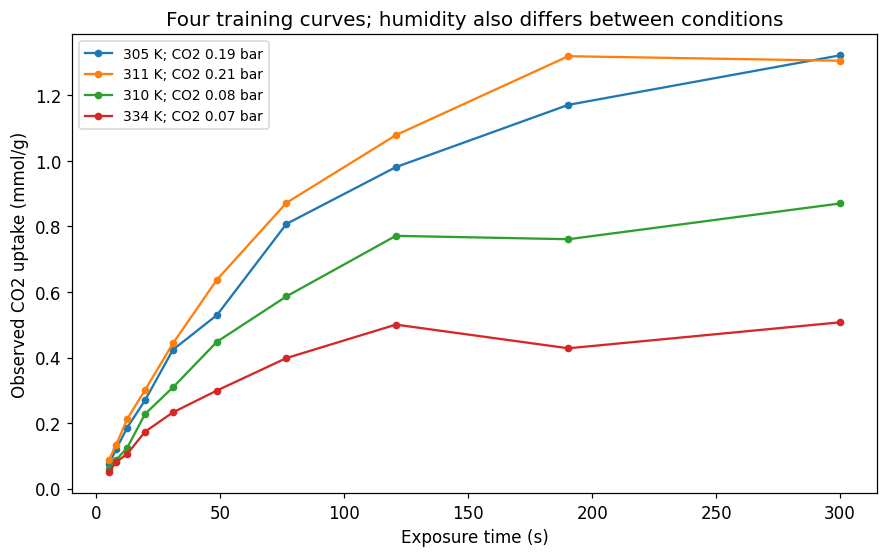

In [6]:
fig, ax = plt.subplots(figsize=(8.2, 5.2))  # Create one readable overview of representative training uptake curves.
for group in train['condition_group'].unique()[:4]:  # Select four distinct training conditions before fitting any model.
    curve = train[train['condition_group'].eq(group)]  # Retain all ten observations from the selected gas condition.
    label = f"{curve['temperature_K'].iloc[0]:.0f} K; CO2 {curve['CO2_partial_pressure_bar'].iloc[0]:.2f} bar"  # Use a compact condition label for the legend.
    ax.plot(curve['exposure_time_s'], curve['uptake_observed'], '-o', markersize=4, label=label)  # Plot the measured time progression without implying these are identical gas conditions.
ax.set(xlabel='Exposure time (s)', ylabel='Observed CO2 uptake (mmol/g)', title='Four training curves; humidity also differs between conditions')  # State the hidden third gas-condition variation.
ax.legend(fontsize=9)  # Keep the representative curve labels readable.
save_plot(fig, '01_training_curves')  # Save the initial experimental overview.

**Read the curves.** Different final values can reflect equilibrium differences, not merely different kinetic speeds. A noisy curve can fluctuate even though the generating mean is monotonic in time.

## 4. Define a transparent symbolic grammar
We search **18 model structures** from three independent choices:

| Choice | Alternatives |
|---|---|
| Equilibrium shape | Linear in CO₂ pressure; CO₂ saturation; CO₂–water competition |
| Temperature dependence | None; equilibrium only; equilibrium and uptake rate |
| Approach to equilibrium | Exponential relaxation; rational saturation in time |

Define dimensionless inputs
$$v=(1000\ \mathrm K)(1/T-1/(318\ \mathrm K)),\quad u=p_C/(0.1\ \mathrm{bar}),$$
$$w=p_W/(0.01\ \mathrm{bar}),\quad s=t/(100\ \mathrm s).$$
For example, the most detailed equilibrium family is
$$q_{eq}=\frac{q_s B_C(v)u}{1+B_C(v)u+B_W(v)w},$$
with $B_C(v)=B_{C,0}\exp(h_Cv)$ and $B_W(v)=B_{W,0}\exp(h_Wv)$. Uptake uses either $1-\exp[-K(v)s]$ or $K(v)s/[1+K(v)s]$, where $K(v)=K_0\exp(-e_kv)$ when temperature-dependent kinetics are included.

Positive scale constants are fitted in logarithmic coordinates. Temperature slopes may be positive or negative within stated bounds. Every candidate has parameters fitted using **training** data; validation chooses among the structural alternatives.

**Boundary on the claim:** this is physics-guided, finite-grammar symbolic regression. Saturation and relaxation templates are supplied in advance. The correct generating structure is included. It is not unconstrained discovery of adsorption physics, and its advantage over a generic polynomial partly reflects this prior knowledge.

In [7]:
def scaled_inputs(x):  # Express temperatures, pressures and times in numerically stable dimensionless coordinates.
    T, pc, pw, t = np.atleast_2d(x).T  # Unpack the four physical inputs.
    return np.column_stack((1000*(1/T-1/318.0), pc/0.1, pw/0.01, t/100.0))  # Use inverse temperature and fixed pressure and time references.
Utrain, Uval = scaled_inputs(train[FEATURES]), scaled_inputs(validation[FEATURES])  # Transform training and validation inputs identically.
log_train = np.log(train['uptake_observed'].to_numpy())+0.5*SIGMA**2  # Correct the known synthetic log-noise mean for parameter fitting.
log_val = np.log(validation['uptake_observed'].to_numpy())+0.5*SIGMA**2  # Apply the same convention to validation scoring.
structures = list(product(['linear', 'saturating', 'competitive'], ['none', 'equilibrium', 'both'], ['exponential', 'rational']))  # Enumerate the 18 predefined structural combinations.
print('Number of symbolic structures:', len(structures))  # Verify that the full finite grammar will be searched.

Number of symbolic structures: 18


**Scaling.** The numerical log response means uptake relative to 1 mmol g$^{-1}$. The known log-noise correction is part of this synthetic experiment; it is not automatically available for a real instrument.

In [8]:
def parameter_names(structure):  # Define which coefficients are needed by a candidate structure.
    equilibrium, temperature, uptake = structure  # Separate the three structural decisions.
    names = ['log_amp'] if equilibrium == 'linear' else ['log_qs', 'log_bc']  # Use a linear amplitude or a saturating capacity and equilibrium coefficient.
    if equilibrium == 'competitive':  # Add a water coefficient only when competition is present.
        names.append('log_bw')  # Permit the candidate to model humidity-dependent inhibition.
    names.append('log_k')  # Give every candidate an effective uptake-rate scale.
    if temperature != 'none':  # Add equilibrium temperature sensitivity when the template allows it.
        names.append('hc')  # Give the CO2 coefficient a fitted inverse-temperature slope.
        if equilibrium == 'competitive':  # Allow water's coefficient its own temperature response.
            names.append('hw')  # Avoid forcing the water and CO2 adsorption slopes to be equal.
    if temperature == 'both':  # Add kinetic temperature sensitivity only in the most detailed temperature family.
        names.append('ek')  # Fit the uptake-rate inverse-temperature slope separately from equilibrium.
    return names  # Return the parameter ordering used consistently in fitting and prediction.

def model_uptake(theta, structure, uinputs):  # Evaluate any candidate expression from its parameters and scaled inputs.
    values = dict(zip(parameter_names(structure), theta))  # Attach parameter names to the fitted numerical coordinates.
    equilibrium, temperature, uptake = structure  # Retrieve the active structural choices.
    v, u, w, s = np.atleast_2d(uinputs).T  # Unpack inverse temperature, CO2 pressure, water pressure and time.
    hc, hw, ek = values.get('hc', 0.0), values.get('hw', 0.0), values.get('ek', 0.0)  # Set omitted temperature effects exactly to zero.
    if equilibrium == 'linear':  # Evaluate the candidate without saturation or water competition.
        qeq = np.exp(values['log_amp']+hc*v)*u  # Make equilibrium proportional to CO2 partial pressure.
    else:  # Evaluate one of the saturating equilibrium families.
        bc = np.exp(values['log_bc']+hc*v)  # Keep the scaled CO2 equilibrium coefficient positive.
        denominator = 1+bc*u  # Introduce a CO2 saturation denominator.
        if equilibrium == 'competitive':  # Include a humidity term only for the competing-site family.
            denominator = denominator+np.exp(values['log_bw']+hw*v)*w  # Add the non-negative competing-water contribution.
        qeq = np.exp(values['log_qs'])*bc*u/denominator  # Calculate equilibrium uptake using the positive fitted capacity.
    exposure = np.exp(values['log_k']-ek*v)*s  # Combine the effective rate and dimensionless exposure time.
    fraction = -np.expm1(-exposure) if uptake == 'exponential' else exposure/(1+exposure)  # Choose the exponential or rational approach-to-equilibrium structure.
    return qeq*fraction  # Return transient uptake in mmol per gram.

**Read the algorithm.** A missing temperature term is zero, not secretly fitted. The same function evaluates every candidate; structure determines which terms and parameters exist. At positive times and CO₂ pressure the fitted log-scale constants guarantee positive uptake.

## 5. Fit parameters inside every structure
For candidate $S$ and coefficients $\theta$, minimise
$$\frac1n\sum_i[\log q_S(x_i;\theta)-(\log q_{obs,i}+\sigma^2/2)]^2.$$
This focuses on relative-scale deviations and matches the synthetic multiplicative noise. Use three starting points per structure and retain the converged fit with the lowest **training** objective. Bounds prevent pathological numerical excursions; a fit hitting a bound must be inspected.

Validation is used only after coefficient fitting. It does not choose the best parameter-fitting start. The search evaluates only the supplied 18 templates and cannot discover a missing family by increasing optimisation iterations.

In [9]:
fit_rng = np.random.default_rng(SEED+4001)  # Keep optimiser starting guesses separate from experimental data and observation noise.
initial = {'log_amp': 0.0, 'log_qs': np.log(2.0), 'log_bc': np.log(0.4), 'log_bw': np.log(0.2), 'log_k': 0.0, 'hc': 1.0, 'hw': 1.0, 'ek': 1.0}  # Supply generic starting scales rather than the generating parameter vector.
fits, rows = {}, []  # Preserve trained candidate fits and their model-selection summaries.
for candidate_id, structure in enumerate(structures):  # Fit every candidate in the predefined symbolic grammar.
    names = parameter_names(structure)  # Determine the coefficients required by this candidate.
    base = np.array([initial[name] for name in names])  # Build its nominal starting point in fitted coordinates.
    lower = np.array([-8.0 if name.startswith('log_') else -10.0 for name in names])  # Set broad lower bounds for scales and temperature slopes.
    upper = np.array([6.0 if name.startswith('log_') else 10.0 for name in names])  # Set broad upper bounds without using the true parameter values.
    starts = [base]+[np.clip(base+fit_rng.normal(0, 0.6, len(base)), lower+1e-5, upper-1e-5) for _ in range(2)]  # Use two perturbed starts in addition to the nominal one.
    attempts = []  # Collect numerical optimisation outcomes for this structure.
    for start_point in starts:  # Fit coefficients independently from each starting guess.
        residual = lambda theta: np.log(model_uptake(theta, structure, Utrain))-log_train  # Define training residuals without consulting validation targets.
        result = least_squares(residual, start_point, bounds=(lower, upper), max_nfev=1800)  # Solve the bounded nonlinear least-squares problem.
        if result.success and np.isfinite(result.fun).all():  # Retain only converged and finite parameter fits.
            attempts.append(result)  # Store a valid training fit for this candidate.
    if not attempts:  # Avoid fabricating a result for a structure whose numerical fits all failed.
        print('No converged fit for candidate', candidate_id, structure)  # Report the failed candidate explicitly.
        continue  # Continue evaluating the remaining structural alternatives.
    fitted = min(attempts, key=lambda item: np.sum(item.fun**2))  # Select the best start using training error only.
    pred_val = model_uptake(fitted.x, structure, Uval)  # Predict independent validation observations with the trained parameters.
    val_rmse = np.sqrt(np.mean((np.log(pred_val)-log_val)**2))  # Calculate the relative-scale validation error.
    complexity = 2*len(names)+{'linear': 3, 'saturating': 8, 'competitive': 13}[structure[0]]+{'none': 0, 'equilibrium': 4, 'both': 8}[structure[1]]+{'exponential': 4, 'rational': 5}[structure[2]]  # Apply a declared within-grammar expression-size proxy.
    bound_hits = int(np.sum((fitted.x-lower < 1e-3) | (upper-fitted.x < 1e-3)))  # Flag coefficients that nearly reach an imposed numerical bound.
    fits[candidate_id] = {'fit': fitted, 'structure': structure, 'names': names}  # Retain the trained model for later validation-based selection.
    rows.append({'id': candidate_id, 'structure': '|'.join(structure), 'parameters': len(names), 'complexity': complexity, 'converged_starts': len(attempts), 'bound_hits': bound_hits, 'train_log_RMSE': np.sqrt(np.mean(fitted.fun**2)), 'validation_log_RMSE': val_rmse})  # Save search evidence without inspecting test responses.
search = pd.DataFrame(rows)  # Assemble the successful candidates in one model-selection table.
if search.empty:  # Prevent downstream interpretation when the core fitting procedure has failed.
    raise RuntimeError('No symbolic candidate converged; inspect initial values and residual definitions.')  # Stop with an informative diagnostic.
display(search.sort_values('validation_log_RMSE').round(5))  # Show all fitted structures, not only the eventual winner.
search.to_csv(RESULTS/'symbolic_structure_search.csv', index=False)  # Save the complete finite-grammar search record.

,id,structure,parameters,complexity,converged_starts,bound_hits,train_log_RMSE,validation_log_RMSE
16,16,competitive|both|exponential,7,39,3,0,0.04997,0.04824
17,17,competitive|both|rational,7,40,3,0,0.06688,0.06723
14,14,competitive|equilibrium|exponential,6,33,3,0,0.11082,0.11141
10,10,saturating|both|exponential,5,30,3,0,0.11887,0.11848
15,15,competitive|equilibrium|rational,6,34,3,0,0.11752,0.11950
12,12,competitive|none|exponential,4,25,3,0,0.12588,0.12394
11,11,saturating|both|rational,5,31,3,0,0.12661,0.12614
13,13,competitive|none|rational,4,26,3,0,0.13182,0.13126
8,8,saturating|equilibrium|exponential,4,24,3,0,0.15768,0.15889
6,6,saturating|none|exponential,3,18,3,0,0.15879,0.15951


**Interpretation.** Compare competition versus no competition, and equilibrium-only versus equilibrium-plus-rate temperature dependence. A larger formula earns its place only if validation improvement justifies it. Bound-hitting fits indicate numerical or identifiability limitations.

Selected structure: ('competitive', 'both', 'exponential')
Selected parameters: {'log_qs': np.float64(1.1228425349997972), 'log_bc': np.float64(-0.7274337090310912), 'log_bw': np.float64(-1.1608339458441295), 'log_k': np.float64(0.41540329550009036), 'hc': np.float64(2.9546222203655823), 'hw': np.float64(4.023620528481619), 'ek': np.float64(2.168069599221084)}


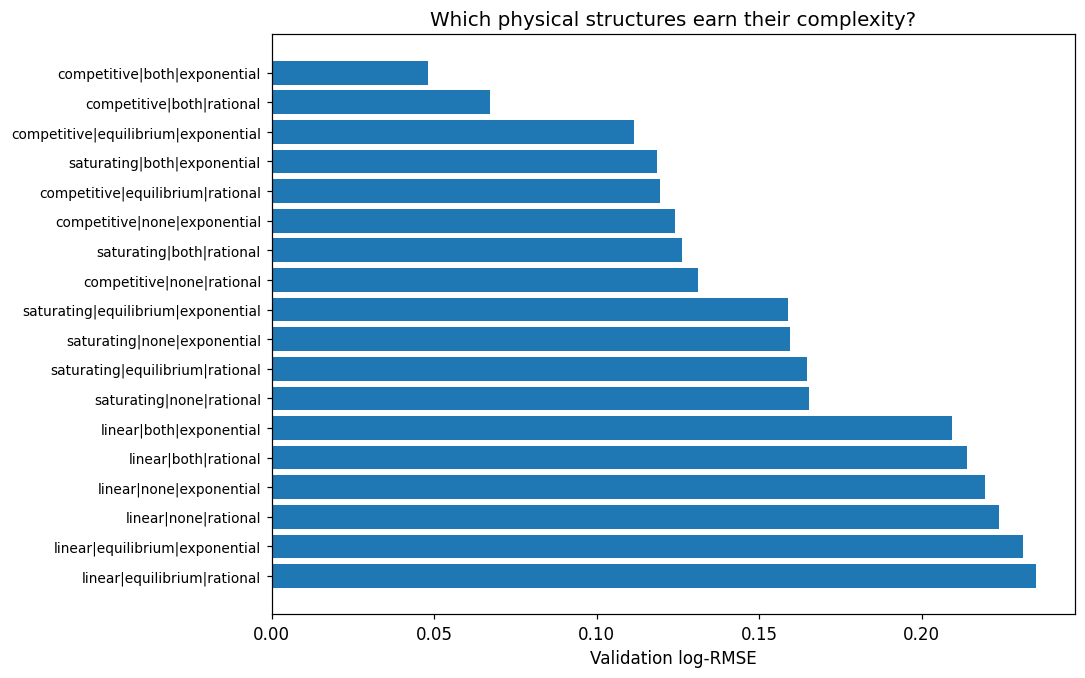

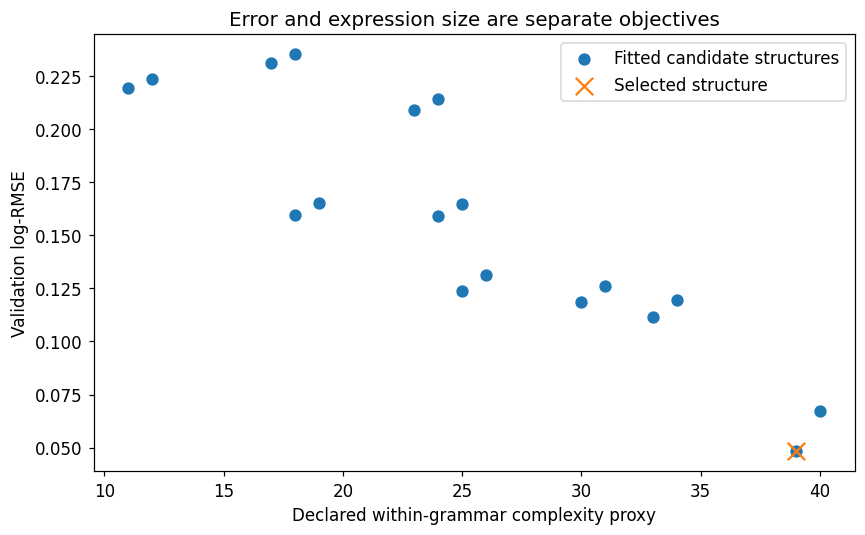

In [10]:
TOLERANCE = 0.003  # Predeclare a small absolute log-RMSE tolerance for preferring a simpler candidate.
shortlist = search[search['validation_log_RMSE'] <= search['validation_log_RMSE'].min()+TOLERANCE]  # Identify models close to the best validation accuracy under the stated rule.
selected = shortlist.sort_values(['complexity', 'validation_log_RMSE']).iloc[0]  # Prefer the simplest candidate inside the validation tolerance.
selected_id = int(selected['id'])  # Recover the selected candidate's stored parameter fit.
chosen = fits[selected_id]  # Freeze its structure and coefficients before opening test outcomes.
structure, fitted, names = chosen['structure'], chosen['fit'], chosen['names']  # Give the selected components clear variable names.
parameter_values = dict(zip(names, fitted.x))  # Record the fitted coordinates by parameter name.
def sr_predict(x):  # Evaluate the frozen symbolic surrogate in physical input units.
    return model_uptake(fitted.x, structure, scaled_inputs(x))  # Apply the original input transformation and the selected expression.
print('Selected structure:', structure)  # State which structural alternatives survived validation.
print('Selected parameters:', parameter_values)  # Show the fitted numerical coordinates rather than assumed generator values.
fig, ax = plt.subplots(figsize=(10, 6.3))  # Create a readable comparison across the complete finite grammar.
ordered = search.sort_values('validation_log_RMSE', ascending=False)  # Order the candidates from largest to smallest validation error.
ax.barh(ordered['structure'], ordered['validation_log_RMSE'])  # Display the performance impact of each structural combination.
ax.set(xlabel='Validation log-RMSE', title='Which physical structures earn their complexity?')  # Identify the independent selection metric.
ax.tick_params(axis='y', labelsize=9)  # Keep long structural labels readable without truncation.
save_plot(fig, '02_candidate_comparison')  # Save the complete model-comparison chart.
fig, ax = plt.subplots(figsize=(8, 5))  # Create a separate complexity-accuracy plot.
ax.scatter(search['complexity'], search['validation_log_RMSE'], s=50, label='Fitted candidate structures')  # Show the structural trade-off in two dimensions.
ax.scatter([selected['complexity']], [selected['validation_log_RMSE']], marker='x', s=130, label='Selected structure')  # Highlight the selected candidate.
ax.set(xlabel='Declared within-grammar complexity proxy', ylabel='Validation log-RMSE', title='Error and expression size are separate objectives')  # State that complexity is a custom comparison scale.
ax.legend()  # Identify the selected model in the candidate set.
save_plot(fig, '03_complexity_tradeoff')  # Save the model-selection geometry.

**Selection boundary.** The validation set has chosen a structure; the test and temperature challenge have not influenced it. The complexity score is not comparable numerically with the pipe notebook’s exponent proxy or with the number of RSM coefficients.

## 6. Display the learned equation and conditional parameter uncertainty
Print the actual fitted expression. Then estimate local parameter uncertainty from the training residual Jacobian. These are approximate intervals conditional on the chosen structure, not uncertainty over all possible adsorption models.

In [11]:
values = parameter_values  # Use the coefficients learned from noisy observations, not the generating parameters.
hc, hw, ek = values.get('hc', 0.0), values.get('hw', 0.0), values.get('ek', 0.0)  # Make omitted temperature dependencies explicit.
if structure[0] == 'linear':  # Construct the displayed equilibrium expression for the selected linear family.
    equilibrium_text = f"({np.exp(values['log_amp']):.6g}*exp({hc:.6g}*v)*u)"  # Print the fitted linear CO2-pressure relationship.
else:  # Construct the displayed expression for a saturating selected family.
    bc_text = f"({np.exp(values['log_bc']):.6g}*exp({hc:.6g}*v))"  # Format the fitted CO2 equilibrium coefficient.
    denominator_text = '1+'+bc_text+'*u'  # Add the CO2 saturation contribution to the denominator.
    if structure[0] == 'competitive':  # Include water only when that structure was actually selected.
        denominator_text += f"+({np.exp(values['log_bw']):.6g}*exp({hw:.6g}*v))*w"  # Print the fitted humidity-competition contribution.
    equilibrium_text = f"({np.exp(values['log_qs']):.6g}*{bc_text}*u/({denominator_text}))"  # Assemble the actual fitted equilibrium capacity expression.
exposure_text = f"({np.exp(values['log_k']):.6g}*exp(-({ek:.6g})*v)*s)"  # Format the fitted dimensionless rate-time product.
uptake_text = '(1-exp(-'+exposure_text+'))' if structure[2] == 'exponential' else '('+exposure_text+'/(1+'+exposure_text+'))'  # Use the selected transient-uptake structure.
equation = 'q_hat = '+equilibrium_text+' * '+uptake_text  # Combine the selected equilibrium and transient factors.
print(equation)  # Display the learned equation in a copyable form.
print('v=1000*(1/T-1/318), u=pCO2/0.1, w=pH2O/0.01, s=t/100; q_hat in mmol/g.')  # Preserve the exact input scaling and output units.
jacobian = fitted.jac  # Retrieve the training residual sensitivities to fitted coordinates.
variance = np.sum(fitted.fun**2)/(len(train)-len(fitted.x))  # Estimate residual log-variance after accounting for fitted parameters.
covariance = variance*np.linalg.pinv(jacobian.T@jacobian)  # Use a pseudoinverse for the local conditional covariance approximation.
standard_errors = np.sqrt(np.maximum(np.diag(covariance), 0))  # Extract non-negative numerical standard-error estimates.
parameter_table = pd.DataFrame({'parameter': names, 'estimate': fitted.x, 'approx_SE': standard_errors, 'approx_lower_95': fitted.x-1.96*standard_errors, 'approx_upper_95': fitted.x+1.96*standard_errors})  # Report local approximate intervals in fitted coordinates.
display(parameter_table.round(5))  # Show coefficient precision without hiding the logarithmic parameterisation.
print('Jacobian rank:', np.linalg.matrix_rank(jacobian), 'of', len(names), '; condition number:', np.linalg.cond(jacobian))  # Flag poor local identifiability or scaling.
parameter_table.to_csv(RESULTS/'selected_parameter_intervals.csv', index=False)  # Save the approximate conditional parameter audit.
(RESULTS/'selected_equation.txt').write_text(equation, encoding='utf-8')  # Save the actual fitted expression for use outside the notebook.

q_hat = (3.07358*(0.483147*exp(2.95462*v))*u/(1+(0.483147*exp(2.95462*v))*u+(0.313225*exp(4.02362*v))*w)) * (1-exp(-(1.51498*exp(-(2.16807)*v)*s)))
v=1000*(1/T-1/318), u=pCO2/0.1, w=pH2O/0.01, s=t/100; q_hat in mmol/g.


,parameter,estimate,approx_SE,approx_lower_95,approx_upper_95
0,log_qs,1.12284,0.01658,1.09034,1.15534
1,log_bc,-0.72743,0.02619,-0.77877,-0.67609
2,log_bw,-1.16083,0.02843,-1.21656,-1.10511
3,log_k,0.41540,0.00699,0.40171,0.42910
4,hc,2.95462,0.05945,2.83810,3.07114
5,hw,4.02362,0.15209,3.72552,4.32172
6,ek,2.16807,0.04531,2.07927,2.25687


Jacobian rank: 7 of 7 ; condition number: 104.45704161365757


147

**Interpretation.** Log-scale parameter intervals should be exponentiated to obtain asymmetric intervals for positive constants. A full uncertainty treatment would also include structural uncertainty, noise-model uncertainty and possible inadequacy of the supplied adsorption templates.

In [12]:
physical_parameters = {'effective_rate_at_318K_s_inverse': np.exp(values['log_k'])/100, 'effective_rate_energy_kJ_mol': ek*R}  # Convert the fitted dimensionless rate and inverse-temperature slope into physical units.
if 'log_qs' in values:  # Report a saturation capacity only for a model that contains one.
    physical_parameters['capacity_mmol_g'] = np.exp(values['log_qs'])  # Recover the positive fitted site capacity.
    physical_parameters['bCO2_at_318K_bar_inverse'] = np.exp(values['log_bc'])/0.1  # Undo the 0.1 bar CO2-pressure reference.
    physical_parameters['CO2_energy_magnitude_kJ_mol'] = hc*R  # Convert the inverse-temperature coefficient into the defined energy convention.
if 'log_bw' in values:  # Report humidity parameters only if competition was selected.
    physical_parameters['bWater_at_318K_bar_inverse'] = np.exp(values['log_bw'])/0.01  # Undo the 0.01 bar water-pressure reference.
    physical_parameters['water_energy_magnitude_kJ_mol'] = hw*R  # Convert the fitted water temperature slope using the same convention.
display(pd.Series(physical_parameters, name='fitted_value').to_frame().round(5))  # Present interpretable model constants in physical units.

,fitted_value
effective_rate_at_318K_s_inverse,0.01515
effective_rate_energy_kJ_mol,18.02633
capacity_mmol_g,3.07358
bCO2_at_318K_bar_inverse,4.83147
CO2_energy_magnitude_kJ_mol,24.56610
bWater_at_318K_bar_inverse,31.32249
water_energy_magnitude_kJ_mol,33.45424


**Mechanistic caution.** A fitted effective energy or rate coefficient is meaningful only within this model and its assumptions. Recovering generator-like values here does not establish the mechanism of a real material.

## 7. Fit RSM baselines and open the independent evaluation sets
Use a full four-input quadratic in coded physical inputs, once for raw uptake and once for corrected log uptake. Both use the same noisy training rows as SR. Their representation and loss differ from the physics-guided grammar, so this is not a universal algorithm benchmark.

In [13]:
def coded(x):  # Express physical inputs relative to the fixed design centre and half-range.
    return (np.atleast_2d(x) - CENTRE) / HALF_RANGE  # Map low and high factor levels to minus and plus one.

def design_matrix(x, degree=2):  # Generate a preselected polynomial structure for RSM.
    poly = PolynomialFeatures(degree=degree, include_bias=True)  # Include an intercept and every term up to the requested degree.
    matrix = poly.fit_transform(coded(x))  # Build polynomial features without using any response data.
    names = poly.get_feature_names_out([f'x{i+1}' for i in range(len(CENTRE))])  # Label the main, squared and interaction terms.
    return pd.DataFrame(matrix, columns=names)  # Preserve interpretable coefficient names in the regression output.

def lack_of_fit(model, x, y):  # Separate within-setting noise from possible inadequacy of the polynomial.
    _, groups = np.unique(np.asarray(x), axis=0, return_inverse=True)  # Identify replicated input conditions.
    pure_sse = sum(np.sum((y[groups == g] - y[groups == g].mean())**2) for g in np.unique(groups))  # Measure variation among repeat observations.
    pure_df = len(y) - len(np.unique(groups))  # Count the pure-error degrees of freedom.
    lof_df = int(model.df_resid) - pure_df  # Allocate remaining residual degrees of freedom to lack of fit.
    lof_sse = max(float(np.sum(model.resid**2)) - pure_sse, 0.0)  # Remove measured repeatability from the residual sum of squares.
    f_stat = (lof_sse/lof_df) / (pure_sse/pure_df)  # Compare lack-of-fit variance with the repeatability estimate.
    p_value = stats.f.sf(f_stat, lof_df, pure_df)  # Evaluate the lack-of-fit upper-tail probability.
    return pd.DataFrame({'source': ['Lack of fit', 'Pure error'], 'sum_squares': [lof_sse, pure_sse], 'df': [lof_df, pure_df], 'F': [f_stat, np.nan], 'p_value': [p_value, np.nan]})  # Present the diagnostic in a compact table.

**Baseline distinction.** The polynomial model does not automatically know saturation, competition or the zero-time condition. The symbolic templates were supplied these possible structures in advance.

,split,model,reference,RMSE,MAE,R_squared,relative_RMSE_pct,negative_predictions
0,test,Raw-response RSM,observed,0.07972,0.06373,0.94979,53.27604,6
1,test,Raw-response RSM,true,0.07619,0.06079,0.95359,52.85399,6
2,test,Log-response RSM,observed,0.17926,0.12469,0.74611,40.79030,0
3,test,Log-response RSM,true,0.17939,0.12401,0.74270,39.78239,0
4,test,Structured SR,observed,0.02796,0.01825,0.99382,4.84355,0
5,test,Structured SR,true,0.00394,0.00274,0.99988,0.75395,0
6,challenge,Raw-response RSM,observed,0.09711,0.07493,0.81591,71.98332,12
7,challenge,Raw-response RSM,true,0.09462,0.07295,0.82863,70.60163,12
8,challenge,Log-response RSM,observed,0.14986,0.10517,0.56163,38.76394,0
9,challenge,Log-response RSM,true,0.14847,0.10530,0.57808,38.03454,0


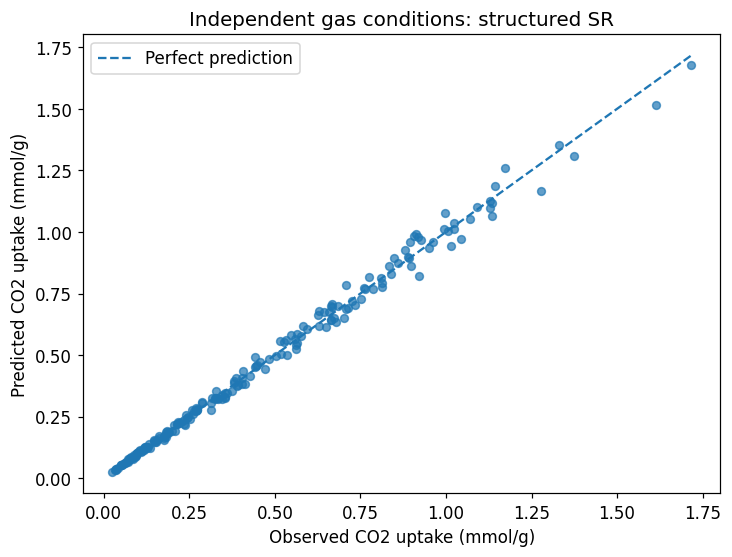

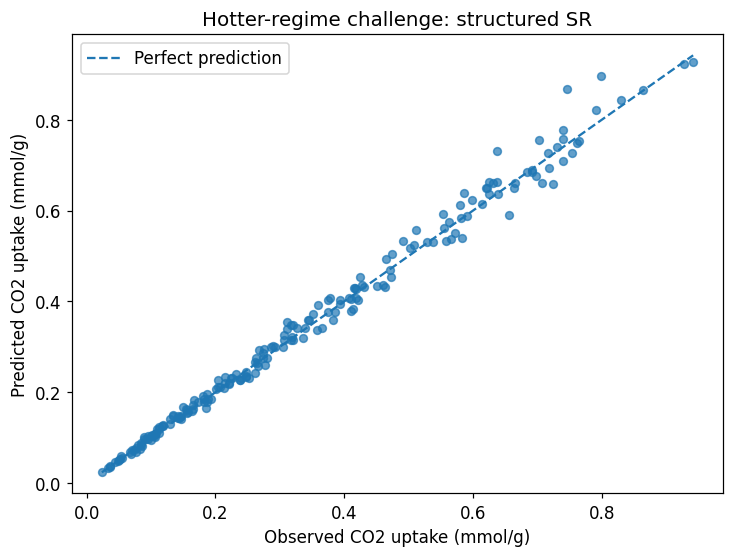

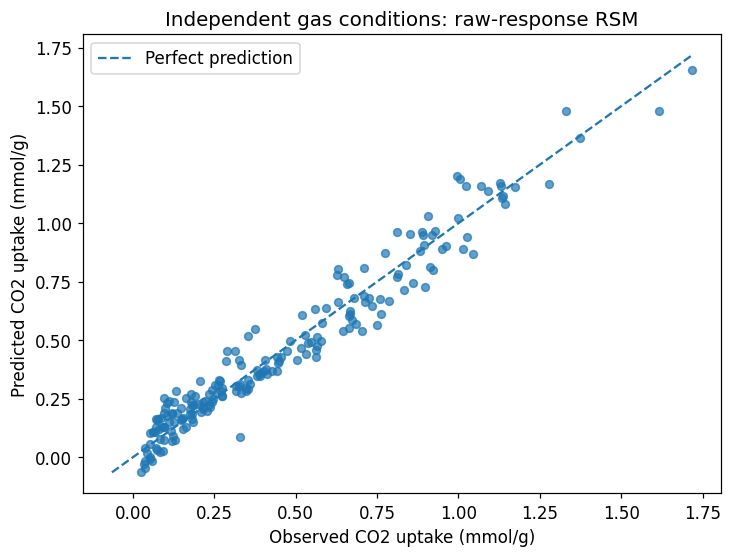

In [14]:
raw_rsm = sm.OLS(train['uptake_observed'], design_matrix(train[FEATURES])).fit()  # Fit the raw-response second-order baseline.
log_rsm = sm.OLS(log_train, design_matrix(train[FEATURES])).fit()  # Fit a positive-output baseline by regressing corrected log uptake.
def all_predictions(x):  # Evaluate the same frozen model set on any physical input table.
    raw = np.asarray(raw_rsm.predict(design_matrix(x)))  # Preserve raw-polynomial negative outputs for auditing.
    positive = np.exp(log_rsm.predict(design_matrix(x)))  # Transform the corrected-log polynomial back to uptake units.
    return {'Raw-response RSM': raw, 'Log-response RSM': np.asarray(positive), 'Structured SR': sr_predict(x)}  # Return labelled predictions without changing any fitted coefficients.
metric_rows = []  # Collect independent accuracy and validity results after selection.
for split, frame in [('test', test), ('challenge', challenge)]:  # Keep interpolation and hotter-temperature extrapolation distinct.
    predictions = all_predictions(frame[FEATURES])  # Evaluate all three representations on identical input conditions.
    output = frame.copy()  # Store every original observation next to its predictions.
    for name, prediction in predictions.items():  # Evaluate each model without selecting on these results.
        output[name] = prediction  # Save its row-level outputs.
        for reference in ['observed', 'true']:  # Separate error against measurements from error against the disclosed generator.
            y = frame['uptake_'+reference].to_numpy()  # Select the intended evaluation reference.
            metric_rows.append({'split': split, 'model': name, 'reference': reference, **metrics(y, prediction), 'relative_RMSE_pct': 100*np.sqrt(np.mean(((prediction-y)/y)**2)), 'negative_predictions': int(np.sum(prediction < 0))})  # Report absolute and relative accuracy together with physical violations.
    output.to_csv(RESULTS/(split+'_predictions.csv'), index=False)  # Preserve independent predictions and group labels.
model_metrics = pd.DataFrame(metric_rows)  # Assemble the complete model comparison.
display(model_metrics.round(5))  # Inspect which representation captures both small and large uptake values.
model_metrics.to_csv(RESULTS/'model_metrics.csv', index=False)  # Save the full accuracy audit.
parity(test['uptake_observed'], sr_predict(test[FEATURES]), 'Independent gas conditions: structured SR', 'CO2 uptake (mmol/g)', '04_test_parity')  # Show symbolic prediction accuracy on unseen gas conditions.
parity(challenge['uptake_observed'], sr_predict(challenge[FEATURES]), 'Hotter-regime challenge: structured SR', 'CO2 uptake (mmol/g)', '05_challenge_parity')  # Display extrapolation separately from interpolation.
parity(test['uptake_observed'], all_predictions(test[FEATURES])['Raw-response RSM'], 'Independent gas conditions: raw-response RSM', 'CO2 uptake (mmol/g)', '06_rsm_parity')  # Compare the polynomial on the same independent observations.

**Interpretation.** Good structured-SR performance in this synthetic challenge is helped by including the correct family in the candidate grammar. It does not imply reliable extrapolation on a real adsorbent with omitted physics.

## 8. Inspect complete held-out uptake curves
Select three test conditions by temperature quantile, not by model error, to avoid showing only favourable examples. Plot the ten noisy observations and a smooth prediction curve at the same gas condition.

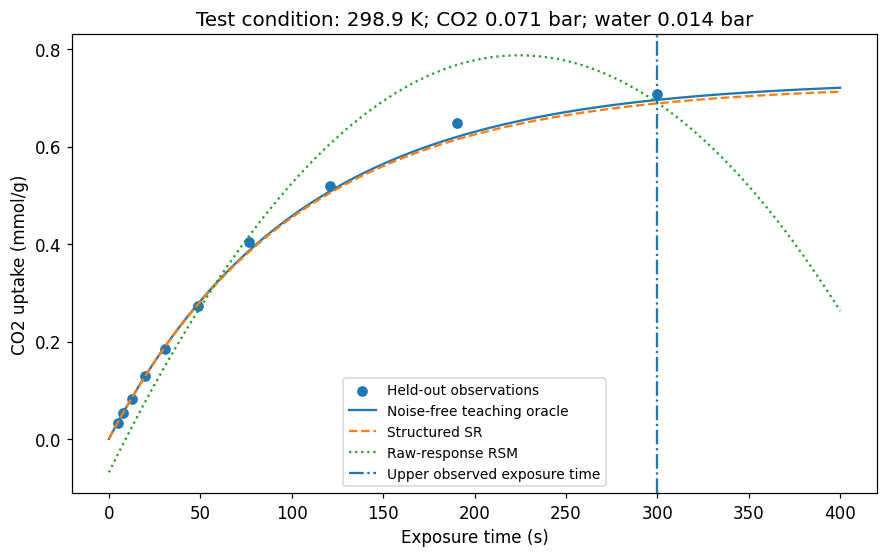

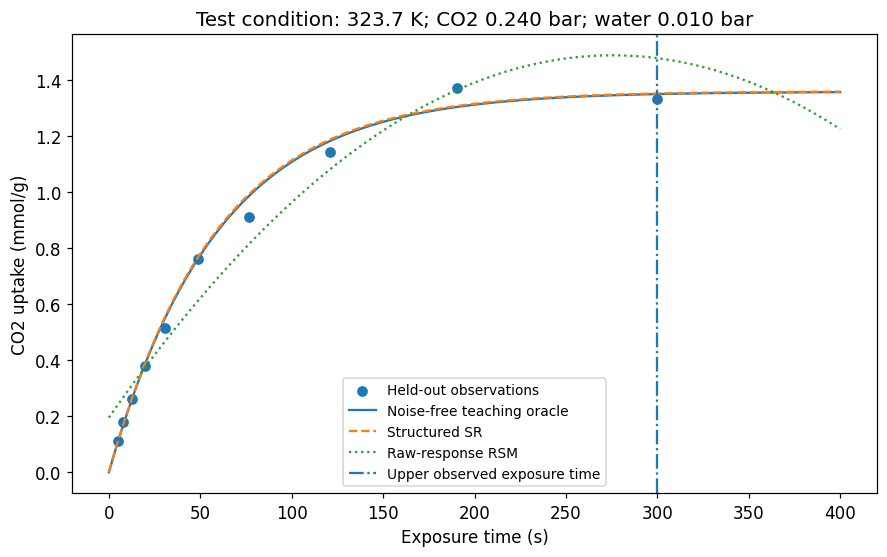

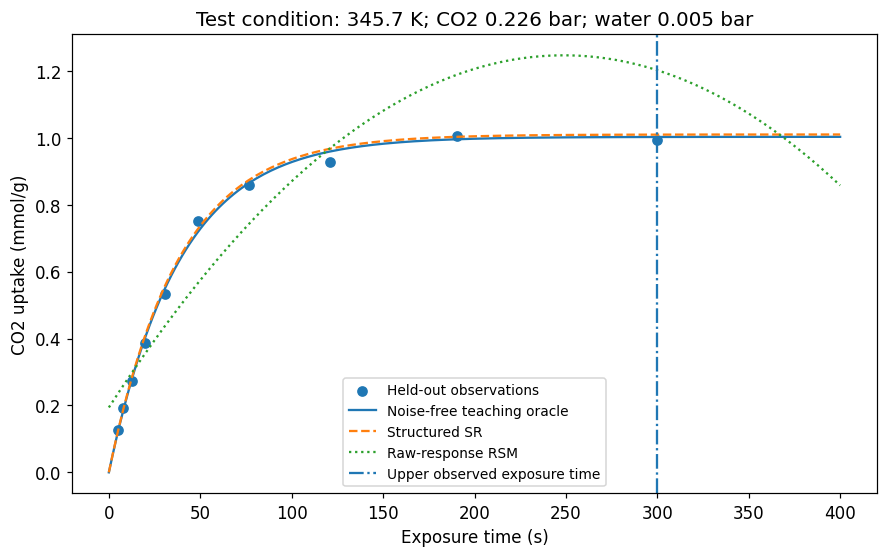

In [15]:
group_conditions = test.groupby('condition_group')[FEATURES[:3]].first().sort_values('temperature_K')  # Summarise and order each independent test gas condition.
chosen_groups = group_conditions.index[[0, len(group_conditions)//2, len(group_conditions)-1]]  # Preselect low, middle and high temperatures rather than favourable residuals.
for number, group in enumerate(chosen_groups, start=7):  # Create one complete, readable figure for each selected held-out condition.
    curve = test[test['condition_group'].eq(group)]  # Retrieve the ten observations for that gas condition.
    gas = curve[FEATURES[:3]].iloc[0].to_numpy()  # Fix temperature and both partial pressures to the held-out condition.
    time_grid = np.linspace(0, 400, 200)  # Display zero time and later uptake in addition to the observed interval.
    xcurve = np.column_stack((np.tile(gas, (len(time_grid), 1)), time_grid))  # Form four-input conditions along a continuous time trajectory.
    fig, ax = plt.subplots(figsize=(8.2, 5.2))  # Allocate a full panel for this condition's time evolution.
    ax.scatter(curve['exposure_time_s'], curve['uptake_observed'], label='Held-out observations')  # Plot only observations from this previously unseen gas condition.
    ax.plot(time_grid, adsorption_truth(xcurve), label='Noise-free teaching oracle')  # Show the generating mean response as a teaching reference.
    ax.plot(time_grid, sr_predict(xcurve), '--', label='Structured SR')  # Evaluate the frozen symbolic equation continuously in time.
    ax.plot(time_grid, all_predictions(xcurve)['Raw-response RSM'], ':', label='Raw-response RSM')  # Reveal polynomial behaviour including its unconstrained zero-time value.
    ax.axvline(300, linestyle='-.', label='Upper observed exposure time')  # Mark time extrapolation clearly instead of presenting it as an observed regime.
    ax.set(xlabel='Exposure time (s)', ylabel='CO2 uptake (mmol/g)', title=f'Test condition: {gas[0]:.1f} K; CO2 {gas[1]:.3f} bar; water {gas[2]:.3f} bar')  # Identify every fixed gas-condition input.
    ax.legend(fontsize=9)  # Keep the model and data labels readable.
    save_plot(fig, f'{number:02d}_held_out_curve')  # Preserve the selected held-out trajectory figure.

**Interpretation.** The symbolic template forces zero uptake at zero time because that condition was built in. The plot outside 5–300 s is a physical-limit and extrapolation diagnostic, not additional independent data.

,group,temperature_K,relative_RMSE_pct,RMSE,MAE,R_squared
7,test_g008,298.90530,3.80575,0.01508,0.01045,0.99602
1,test_g002,301.82072,4.94986,0.05099,0.03646,0.99213
0,test_g001,304.74664,4.73002,0.03589,0.02303,0.98861
9,test_g010,307.75201,3.62669,0.01496,0.00927,0.99603
3,test_g004,309.59850,3.76942,0.00982,0.00708,0.99456
17,test_g018,311.13352,4.50956,0.01858,0.01331,0.99669
16,test_g017,313.21761,6.12875,0.04272,0.02489,0.98865
18,test_g019,316.98865,5.07349,0.03480,0.02551,0.99232
19,test_g020,318.19339,5.49869,0.02534,0.01940,0.99346
6,test_g007,320.77713,5.11560,0.01741,0.01355,0.99442


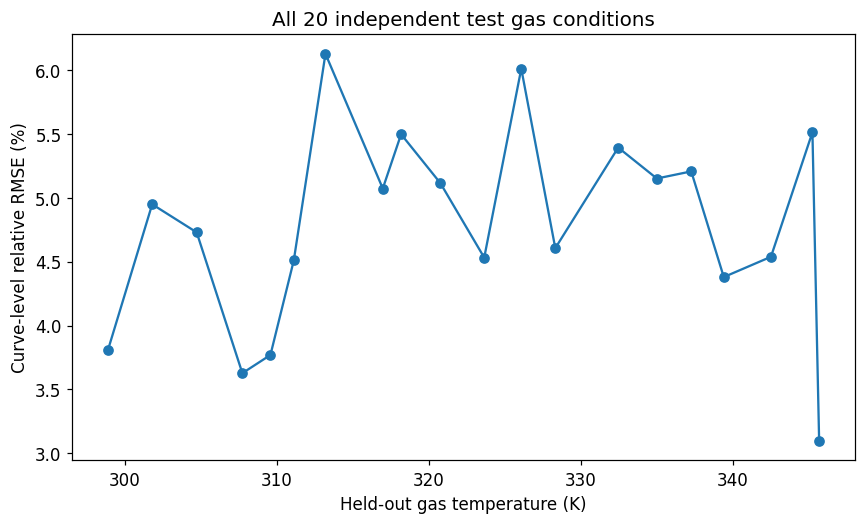

In [16]:
condition_errors = []  # Summarise accuracy at the gas-condition level rather than only at the observation-row level.
for group, frame in test.groupby('condition_group'):  # Keep all time points for a gas condition together.
    observed, predicted = frame['uptake_observed'].to_numpy(), sr_predict(frame[FEATURES])  # Compare the complete held-out curve with fixed-model predictions.
    condition_errors.append({'group': group, 'temperature_K': frame['temperature_K'].iloc[0], 'relative_RMSE_pct': 100*np.sqrt(np.mean(((predicted-observed)/observed)**2)), **metrics(observed, predicted)})  # Calculate condition-specific errors without discarding difficult curves.
condition_table = pd.DataFrame(condition_errors).sort_values('temperature_K')  # Order conditions by a physical variable rather than the outcome.
display(condition_table.round(5))  # Show error variability across all 20 independent test conditions.
condition_table.to_csv(RESULTS/'condition_level_test_errors.csv', index=False)  # Save the grouped evaluation audit.
fig, ax = plt.subplots(figsize=(8, 4.9))  # Create a condition-level relative-error plot.
ax.plot(condition_table['temperature_K'], condition_table['relative_RMSE_pct'], 'o-')  # Show whether a particular temperature region has larger full-curve errors.
ax.set(xlabel='Held-out gas temperature (K)', ylabel='Curve-level relative RMSE (%)', title='All 20 independent test gas conditions')  # State the effective evaluation unit.
save_plot(fig, '10_condition_errors')  # Save the group-level accuracy figure.

**Interpretation.** A low aggregate error can hide a difficult operating condition. Curve-level reporting makes the intended generalisation claim clearer than quoting the number of time-point rows alone.

## 9. Audit physical limits and temperature–humidity effects
Check non-negative uptake, zero initial uptake, increasing uptake with time and non-increasing uptake with humidity under the selected competing-site assumption. These checks do not replace independent physical validation.

,check,passed
0,All sampled predictions finite,True
1,No negative uptake,True
2,Zero uptake at zero time,True
3,Uptake non-decreasing with time,True
4,Uptake non-increasing with water,True


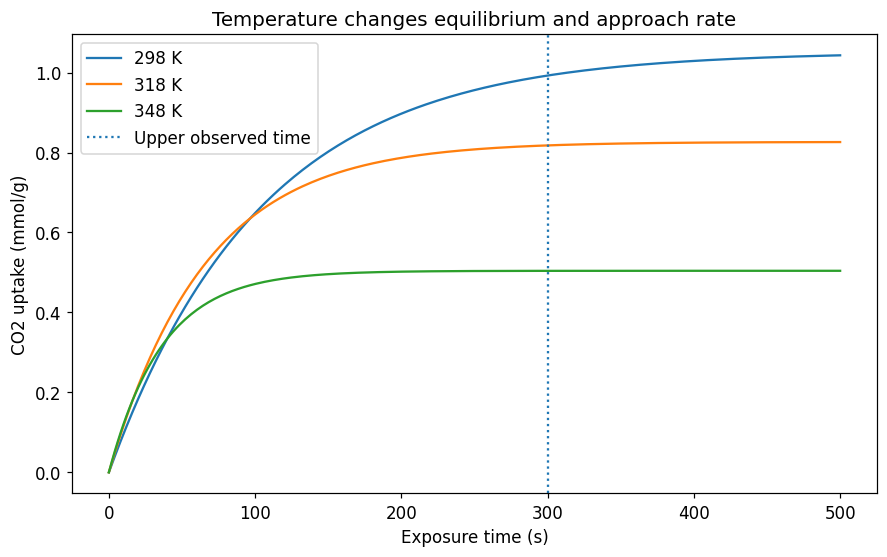

In [17]:
audit_rng = np.random.default_rng(SEED+4002)  # Use new in-domain locations for a structural validity audit.
audit_x = lhs(500, BOUNDS, audit_rng)  # Sample the declared operating box without using new targets to refit the model.
q = sr_predict(audit_x)  # Predict uptake at the sampled conditions.
xzero = audit_x.copy()  # Create an independent array for the zero-time limit.
xzero[:, 3] = 0  # Set exposure time to the physically stated initial condition.
xlater = audit_x.copy()  # Create a nearby later-time comparison at the same gas conditions.
xlater[:, 3] += 0.1  # Apply a small positive time increment for a finite-difference monotonicity check.
xwetter = audit_x.copy()  # Create a nearby higher-humidity comparison.
xwetter[:, 2] += 1e-6  # Add a small positive water partial-pressure increment.
audit = pd.DataFrame({'check': ['All sampled predictions finite', 'No negative uptake', 'Zero uptake at zero time', 'Uptake non-decreasing with time', 'Uptake non-increasing with water'], 'passed': [bool(np.isfinite(q).all()), bool(np.min(q) >= -1e-12), bool(np.max(np.abs(sr_predict(xzero))) < 1e-12), bool(np.min(sr_predict(xlater)-q) >= -1e-10), bool(np.max(sr_predict(xwetter)-q) <= 1e-10)]})  # Report validity tests without pretending that they prove a mechanism.
display(audit)  # Show both successful and unsuccessful physical checks honestly.
audit.to_csv(RESULTS/'physical_audit.csv', index=False)  # Preserve the sampled structural audit.
fig, ax = plt.subplots(figsize=(8.2, 5.2))  # Create a temperature-comparison plot at fixed partial pressures.
time_grid = np.linspace(0, 500, 250)  # Inspect the approach towards equilibrium over a wider time interval.
for temperature in [298, 318, 348]:  # Compare three stated temperatures inside the fitted range.
    curve_inputs = np.column_stack((np.full(len(time_grid), temperature), np.full(len(time_grid), 0.1), np.full(len(time_grid), 0.01), time_grid))  # Hold CO2 and water partial pressures fixed across temperature curves.
    ax.plot(time_grid, sr_predict(curve_inputs), label=f'{temperature} K')  # Show how the selected model balances equilibrium and effective rate.
ax.axvline(300, linestyle=':', label='Upper observed time')  # Identify where the display exceeds the time training range.
ax.set(xlabel='Exposure time (s)', ylabel='CO2 uptake (mmol/g)', title='Temperature changes equilibrium and approach rate')  # Avoid implying that a single monotonic temperature effect is guaranteed.
ax.legend()  # Identify temperatures and the observation boundary.
save_plot(fig, '11_temperature_effects')  # Save the physical temperature-interpretation figure.

**Interpretation.** Faster approach to equilibrium at a higher temperature can coexist with lower equilibrium capacity. The plots must be interpreted at a specified exposure time; “temperature improves adsorption” is incomplete without that context.

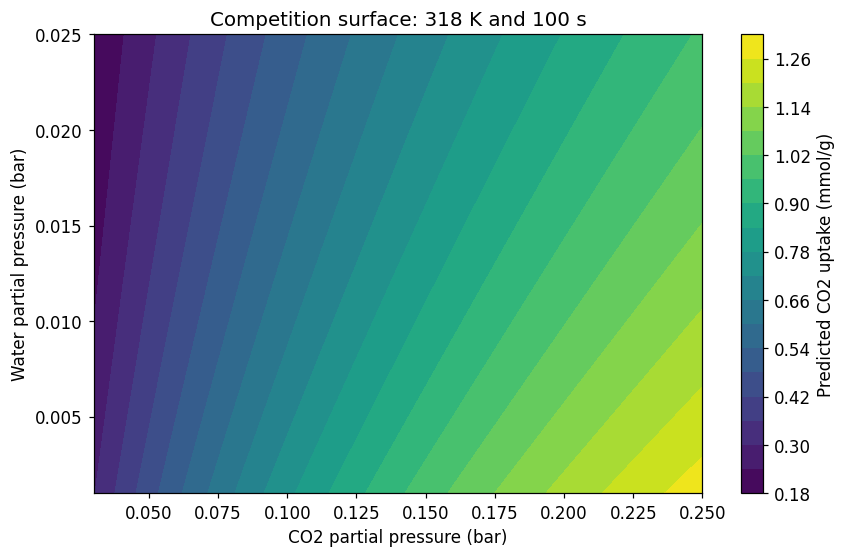

In [18]:
pc_grid, pw_grid = np.meshgrid(np.linspace(0.03, 0.25, 65), np.linspace(0.001, 0.025, 65))  # Form an in-domain CO2-pressure and humidity grid.
xgrid = np.column_stack((np.full(pc_grid.size, 318.0), pc_grid.ravel(), pw_grid.ravel(), np.full(pc_grid.size, 100.0)))  # Fix temperature at 318 K and exposure at 100 seconds.
fig, ax = plt.subplots(figsize=(8, 5.2))  # Create one two-input response-surface figure.
contour = ax.contourf(pc_grid, pw_grid, sr_predict(xgrid).reshape(pc_grid.shape), levels=20)  # Evaluate the selected symbolic model over the pressure combinations.
fig.colorbar(contour, ax=ax, label='Predicted CO2 uptake (mmol/g)')  # State the response units for the contour scale.
ax.set(xlabel='CO2 partial pressure (bar)', ylabel='Water partial pressure (bar)', title='Competition surface: 318 K and 100 s')  # State the two held input conditions.
save_plot(fig, '12_humidity_surface')  # Preserve the multivariable chemical-engineering interpretation.

**Engineering takeaway.** A surrogate can represent saturation, competition and transient uptake compactly. Real capture design still requires evidence for the chosen adsorption model and additional balances for bed transport, heat effects, depletion and regeneration.

## 10. Exercises and model limitations
**A · Missing physics:** remove the competitive equilibrium option from `structures` and repeat fitting. Inspect systematic humidity residuals rather than claiming a more complex surviving model has discovered water competition.

**B · Identifiability:** retain only long-time observations and inspect the rate-parameter uncertainty. Why does equilibrium-heavy data contain little information about an already completed transient?

**C · Validation unit:** explain how a row-wise split changes the generalisation question when all ten time points share a gas condition.

**D · Extrapolation:** add an adsorption-heat effect or a different water mechanism to a new generator. The present challenge is favourable because the correct structural family remains valid.

<details><summary><b>Instructor interpretation</b></summary>
Model selection can choose only among supplied families. Long-time saturation can identify equilibrium better than rate, and local Jacobian intervals may reveal weak parameter identifiability. Grouped splits test new gas conditions, whereas row-wise splits partly test new times at known conditions. The zero-time and positivity properties are built into the symbolic grammar; they were not independently discovered from the observations. Approximate parameter intervals condition on the selected structure and omit structural and physical-model uncertainty.
</details>

In [19]:
Xtrain_optional, Xval_optional, Xtest_optional = Utrain, Uval, scaled_inputs(test[FEATURES])  # Supply the same four transformed physical inputs to the optional evolutionary search.
ytrain_optional = train['uptake_observed'].to_numpy()  # Use noisy training uptake in mmol per gram for the optional raw-response objective.
yval_optional = validation['uptake_observed'].to_numpy()  # Keep the independent validation target separate.
ytest_optional = test['uptake_observed'].to_numpy()  # Reserve test uptake for optional reporting after equation selection.

**Preparation for the extension.** These arrays do not run any additional algorithm or install a dependency.

## Optional extension · evolutionary symbolic regression with PySR
The core search above enumerates a **restricted grammar**. This extension searches a broader space of expression trees with a different algorithm. It is **disabled by default**, is not required to complete the lesson, and is not part of the saved core execution check. Enabling it installs PySR and may initialise/download its Julia runtime; internet access and a working hosted runtime are required.

The search below uses unweighted squared error on the scaled raw output. That differs from the core log-residual objective: treat it as an algorithm demonstration, not a controlled accuracy benchmark. The validation set selects among the returned equations, and non-finite or non-positive candidates receive an infinite validation score. Exact recovery is not guaranteed with this deliberately limited search budget.

Set `RUN_PYSR = True` only after the core notebook has completed. Search settings and package versions can change the discovered expressions.

In [20]:
RUN_PYSR = False  # Keep the complete core lesson runnable without Julia or an additional package installation.
if RUN_PYSR:  # Enter the optional evolutionary search only when the learner explicitly enables it.
    if importlib.util.find_spec('pysr') is None:  # Avoid reinstalling an already available PySR package.
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pysr'])  # Install the optional Python interface in the current runtime.
    from pysr import PySRRegressor  # Import the evolutionary search interface and initialise its Julia dependency when needed.
    evolutionary = PySRRegressor(niterations=40, binary_operators=['+', '-', '*', '/'], unary_operators=['exp', 'square'], maxsize=24, random_state=SEED, parallelism='serial', deterministic=True, progress=False)  # Define a restrained expression-tree search with reproducible serial settings.
    evolutionary.fit(Xtrain_optional, ytrain_optional)  # Fit using only the supplied noisy training targets.
    optional_rows = []  # Collect independent validation scores for the discovered expression candidates.
    for i in range(len(evolutionary.equations_)):  # Consider each equation returned by the search.
        pv = np.asarray(evolutionary.predict(Xval_optional, index=i))  # Evaluate that expression on untouched validation inputs.
        valid = np.isfinite(pv).all() and np.all(pv > 0)  # Reject undefined, overflowing or non-positive predictions for this positive response.
        error = float(np.sqrt(np.mean((np.log(pv)-np.log(yval_optional))**2))) if valid else np.inf  # Use a relative-scale validation metric without silently clipping invalid outputs.
        optional_rows.append({'equation_index': i, 'validation_log_RMSE': error})  # Record the score separately from training search fitness.
    optional_scores = pd.DataFrame(optional_rows)  # Assemble the validation comparison table.
    display(evolutionary.equations_)  # Show the discovered expressions and their training complexity measures.
    display(optional_scores)  # Show how the independent validation ranking differs from the training ranking.
    finite = optional_scores[np.isfinite(optional_scores['validation_log_RMSE'])]  # Retain only candidates valid on every validation input.
    if len(finite):  # Avoid selecting an invalid expression when every candidate fails the domain check.
        optional_best = int(finite.loc[finite['validation_log_RMSE'].idxmin(), 'equation_index'])  # Select the candidate from validation performance only.
        pt = np.asarray(evolutionary.predict(Xtest_optional, index=optional_best))  # Evaluate the chosen expression on independent test inputs.
        display(pd.DataFrame([metrics(ytest_optional, pt)]))  # Report test metrics in the scaled output units.
        print('Selected optional equation:', evolutionary.sympy(index=optional_best))  # Print the actual expression found in this optional run.
    else:  # Report failure honestly instead of presenting a fabricated symbolic model.
        print('No discovered equation was valid across the validation set; retain the core model for this lesson.')  # Explain the outcome without altering held-out results.
else:  # Make the skipped optional extension explicit in a normal Run all execution.
    print('Optional PySR search skipped. The fully executed core results above remain available.')  # Distinguish tested core outputs from an unexecuted extension.

Optional PySR search skipped. The fully executed core results above remain available.


**Comparison question.** Which structural information did the restricted grammar provide in advance? Which did the evolutionary search need to construct? Compare accuracy, complexity and validity separately, and keep the test set out of repeated search tuning.

## Export your results
All figures, generated observations, model coefficients and prediction tables are saved in the case-specific results folder. Download the archive before disconnecting a temporary runtime. Use **File → Download → Download .ipynb** to retain your own comments and outputs.

In [21]:
model_spec = {'method': 'restricted physics-guided template structure search', 'structure': list(structure), 'parameter_names': names, 'fitted_coordinates': fitted.x.tolist(), 'noise_sigma': SIGMA, 'seed': SEED, 'input_definition': 'v=1000*(1/T-1/318), u=pCO2/0.1, w=pH2O/0.01, s=t/100', 'output_unit': 'mmol/g'}  # Record the model's structure, coefficients and scaling conventions.
(RESULTS/'selected_model.json').write_text(json.dumps(model_spec, indent=2), encoding='utf-8')  # Save a machine-readable equation specification for independent evaluation.

599

In [22]:
archive = shutil.make_archive(str(RESULTS) + '_results', 'zip', RESULTS)  # Bundle this run's tables and figures into one archive.
display(FileLink(archive))  # Display a file link in notebook interfaces that support local downloads.
DOWNLOAD_RESULTS = False  # Set this switch to True to start a Colab browser download.
if DOWNLOAD_RESULTS:  # Avoid an unsolicited download during normal Run all execution.
    try:  # Use Colab's helper only in an environment where it exists.
        from google.colab import files  # Load Google's browser-download interface.
        files.download(archive)  # Copy the result archive to the learner's computer.
    except ImportError:  # Keep the same notebook usable in standard Jupyter.
        print('Use the link above or the notebook file browser.')  # Explain the non-Colab download route.
print('Core workflow finished: all displayed core results were calculated in this run.')  # Mark successful completion of the lesson.

/mnt/data/Colab_Teaching_Notebooks/results_04_sr_co2_adsorption_results.zip

Core workflow finished: all displayed core results were calculated in this run.


**Save your work.** Downloading the archive does not itself save edits to the notebook. Save both the `.ipynb` and the results archive.

## Sources and scope
All numerical chemical parameters and synthetic observations are teaching assumptions. The sources support the modelling concepts, not those invented parameter values.

- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)
- [NIST: response surface designs](https://www.itl.nist.gov/div898/handbook/pri/section3/pri336.htm)
- [statsmodels: ordinary least squares](https://www.statsmodels.org/stable/examples/notebooks/generated/ols.html)
- [SciPy: bounded nonlinear least squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)
- [CADET: multicomponent Langmuir model](https://cadet.github.io/v5.1.X/modelling/binding/multi_component_langmuir.html)
- [CADET: linear-driving-force modelling](https://cadet.github.io/v5.1.X/modelling/binding/index.html)
- [PySR method paper](https://arxiv.org/abs/2305.01582)
- [PySR API reference](https://ai.damtp.cam.ac.uk/pysr/api)


**Verification boundary.** The supplied core workflow was executed in a clean local Python kernel and its outputs are saved. This is not a claim of execution in Google's hosted runtime. Any optional PySR section is disabled by default and excluded from the core execution check.